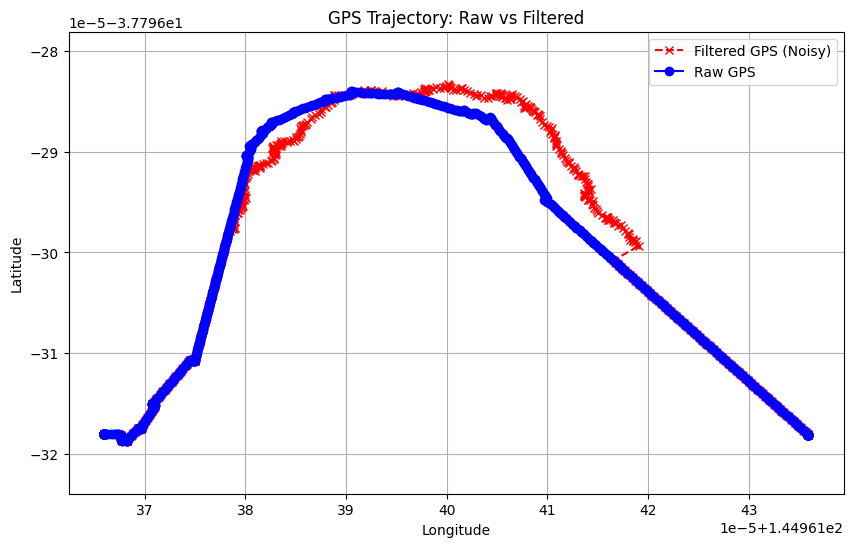

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

#date_tag='20250502_123008'
#date_tag='20250502_015603'         # Initial choppy data
date_tag='20250502_121336'         # Fixed by removing linear accel  


# Load raw and filtered GPS data
raw_df = pd.read_csv('raw_gps_'+date_tag+'.csv')
filtered_df = pd.read_csv('filtered_gps_'+date_tag+'.csv')

# Plot Latitude vs Longitude for both datasets
plt.figure(figsize=(10, 6))

plt.plot(filtered_df['longitude'], filtered_df['latitude'], label='Filtered GPS (Noisy)', marker='x', linestyle='--', color='red')
plt.plot(raw_df['longitude'], raw_df['latitude'], label='Raw GPS', marker='o', linestyle='-', color='blue')

plt.title('GPS Trajectory: Raw vs Filtered')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()


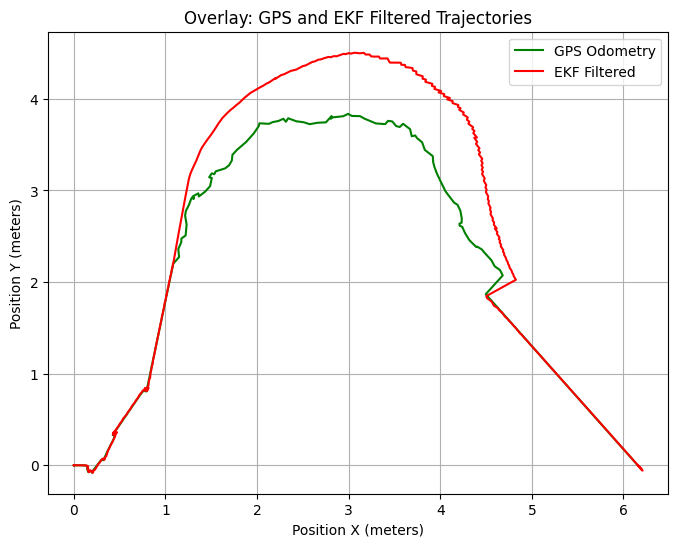

In [28]:
# Load the datasets
gps_df = pd.read_csv('odometry_gps_'+date_tag+'.csv')
filtered_df = pd.read_csv('odometry_filtered_'+date_tag+'.csv')

# Plot both GPS and EKF filtered trajectories
plt.figure(figsize=(8, 6))

# GPS path in green
plt.plot(gps_df['pos_x'], gps_df['pos_y'], linestyle='-', color='green', label='GPS Odometry')

# EKF filtered path 
plt.plot(filtered_df['pos_x'], filtered_df['pos_y'], linestyle='-', color='red', label='EKF Filtered')


# Labels and legend
plt.title('Overlay: GPS and EKF Filtered Trajectories')
plt.xlabel('Position X (meters)')
plt.ylabel('Position Y (meters)')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()



## State Vector in 2D Mode

The UKF tracks the robot state as:

$$
\mathbf{x} =
\begin{bmatrix}
x \\
y \\
\theta \\
\dot{x} \\
\dot{y} \\
\dot{\theta}
\end{bmatrix}
$$

Where:
- **x, y**: Position in the map frame
- **θ**: Yaw angle (robot orientation)
- **ẋ, ẏ**: Linear velocity in the world frame
- **θ̇**: Angular velocity (yaw rate)

---

## 1. Motion (Prediction) Model

The prediction step uses a **constant velocity** model.
Without acceleration input, it simplifies to:

$$
\mathbf{x}_{k+1} =
\begin{bmatrix}
x_k + \dot{x}_k \Delta t \\
y_k + \dot{y}_k \Delta t \\
\theta_k + \dot{\theta}_k \Delta t \\
\dot{x}_k \\
\dot{y}_k \\
\dot{\theta}_k
\end{bmatrix}
$$

> Note: Acceleration states are not modeled or fused.

---

## 2. Measurement Models

### GPS Odometry (`/odometry/gps_scaled`)

Provides:

$$
\mathbf{z}_{gps} =
\begin{bmatrix}
x \\
y
\end{bmatrix}
$$

Update equation:

$$
\mathbf{x}_{k+1} = \mathbf{x}_{k+1} + K \left( \mathbf{z}_{gps} - H \mathbf{x}_{k+1} \right)
$$

Where:
- **K** is the Kalman gain
- **H** is the measurement matrix extracting `x`, `y` from the state

---

### IMU (`/imu_scaled`)

Provides:

$$
\mathbf{z}_{imu} =
\begin{bmatrix}
\theta \\
\dot{\theta}
\end{bmatrix}
$$

> No linear acceleration is fused (you’ve disabled it in `imu0_config`).

---

## 3. Covariance Update (UKF)

The UKF propagates uncertainty using sigma points:

$$
P_{k+1} = \sum_i W_i \left( \chi^i_{k+1} - \bar{\mathbf{x}}_{k+1} \right) \left( \chi^i_{k+1} - \bar{\mathbf{x}}_{k+1} \right)^T
$$

Where:
- **χᵢ** are the sigma points
- **Wᵢ** are their associated weights
- **x̄ₖ₊₁** is the predicted mean

---

## Summary of Core Components

| Component            | Equation Type                        |
|----------------------|--------------------------------------|
| Motion model         | Constant velocity                    |
| GPS measurement      | Direct update of `x`, `y`            |
| IMU measurement      | Orientation + angular velocity (yaw)|
| Covariance dynamics  | UKF sigma point propagation          |


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load your data (replace with actual file or DataFrame)
df = pd.read_csv('imu_20250502_014724.csv')

# Time step
df['dt'] = df['time'].diff().fillna(0)

# Compute speed (magnitude of X and Y acceleration)
df['speed'] = np.sqrt(df['linear_acc_x']**2 + df['linear_acc_y']**2)

# Estimate yaw (heading) by integrating angular velocity z (gyroscope)
df['yaw'] = np.cumsum(df['angular_vel_z'] * df['dt'])

# Smooth yaw using rolling average
df['yaw'] = df['yaw'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')

# Optional: smooth acceleration
df['speed'] = df['speed'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')

# Initialize position arrays
x, y = [0], [0]

# Dead reckoning using yaw and speed
for i in range(1, len(df)):
    psi = df['yaw'].iloc[i]
    v = df['speed'].iloc[i]
    dx = v * df['dt'].iloc[i] * np.cos(psi)
    dy = v * df['dt'].iloc[i] * np.sin(psi)
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)

# Store in DataFrame for plotting
traj = pd.DataFrame({'X': x, 'Y': y, 'Yaw': df['yaw'], 'Speed': df['speed'], 'Time': df['time']})

# Optional: Rotate for alignment (e.g., 90° CCW)
traj['X_rot'] = traj['Y']
traj['Y_rot'] = traj['X']

# Plot the rotated path
plt.figure(figsize=(8, 6))
plt.plot(traj['Y_rot'], traj['X_rot'], label='IMU Trajectory (Yaw-based)', color='purple')
plt.title("2D IMU Trajectory using Yaw and Speed")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'imu_20250502_014724.csv'

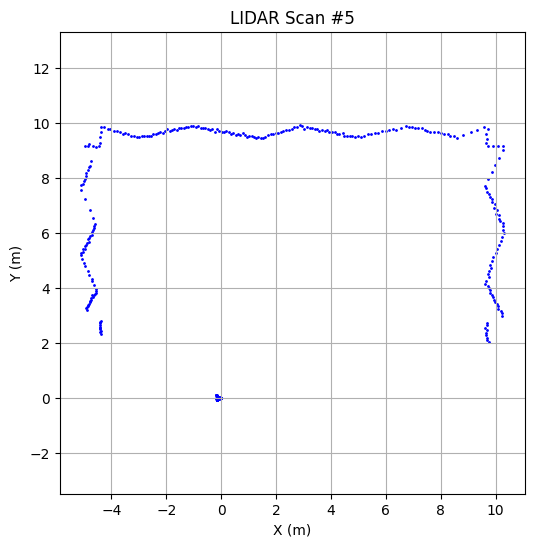

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import json
import re

# Load the LIDAR CSV
df = pd.read_csv('lidar_20250411_113244.csv')

# Select a scan index to visualize
scan_index = 5  # Change this index as needed

# Get the string from the CSV
ranges_str = df['ranges'].iloc[scan_index]

# Clean the string if necessary (remove 'nan', 'inf', etc.)
ranges_str = re.sub(r'(?<![\d.])-?nan|inf', '0', ranges_str.lower())

# Convert to a list using json
ranges = np.array(json.loads(ranges_str))

# Generate angles (assuming 360° scan)
angles = np.linspace(-np.pi, np.pi, len(ranges))

# Convert polar to Cartesian
x = ranges * np.cos(angles)
y = ranges * np.sin(angles)

# Plot the scan
plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=1, color='blue')
plt.title(f'LIDAR Scan #{scan_index}')
plt.xlabel('X (m)')
plt.ylabel('Y (m)')
plt.axis('equal')
plt.grid(True)
plt.show()


C:\Users\meljo\AppData\Local\Temp\ipykernel_30404\3940651340.py:49: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  imu_df['speed'] = imu_df['speed'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')
C:\Users\meljo\AppData\Local\Temp\ipykernel_30404\3940651340.py:50: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  imu_df['yaw'] = imu_df['yaw'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')


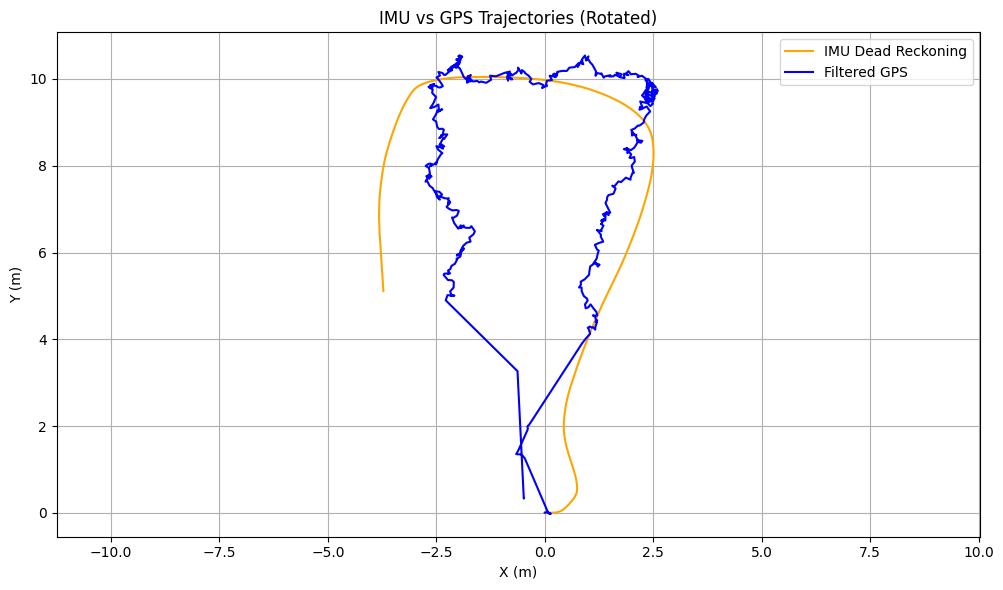

In [ ]:
# Adaptive Unscented Kalman Filter (A-UKF) Fusion of IMU and GPS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Adaptive UKF Class ---
class AdaptiveUKF:
    def __init__(self, dt):
        self.dt = dt
        self.dim_x = 3  # [x, y, v]
        self.dim_z = 3  # [x, y, v]

        self.x = np.array([0, 0, 0])
        self.P = np.diag([10, 10, 1])
        self.Q = np.diag([0.2, 0.2, 0.1])
        self.R = np.diag([0.1, 0.1, 0.05])

        self.F = np.eye(3)
        self.F[0, 2] = dt
        self.F[1, 2] = dt

        self.H = np.eye(3)

    def predict(self, x, y, v, yaw):
        self.x = np.array([x, y, v])
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, gps_x, gps_y, gps_v, cov_x, cov_y, cov_v):
        z = np.array([gps_x, gps_y, gps_v])
        self.R = np.diag([cov_x, cov_y, cov_v])

        y = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)

        self.x = self.x + K @ y
        I = np.eye(self.dim_x)
        self.P = (I - K @ self.H) @ self.P

# --- Load CSV Files ---
imu_df = pd.read_csv('imu_20250411_113244.csv')
raw_gps = pd.read_csv('raw_gps_20250411_113244.csv')
filtered_gps = pd.read_csv('filtered_gps_20250411_113244.csv')

# --- Preprocess IMU ---
imu_df['dt'] = imu_df['time'].diff().fillna(0)
imu_df['speed'] = np.sqrt(imu_df['linear_acc_x']**2 + imu_df['linear_acc_y']**2)
imu_df['yaw'] = np.cumsum(imu_df['angular_vel_z'] * imu_df['dt'])
imu_df['speed'] = imu_df['speed'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')
imu_df['yaw'] = imu_df['yaw'].rolling(window=10, center=True).mean().fillna(method='bfill').fillna(method='ffill')

# Rotate for alignment (90° clockwise)
imu_df['X'] = imu_df['speed'] * np.cos(imu_df['yaw']) * imu_df['dt']
imu_df['Y'] = imu_df['speed'] * np.sin(imu_df['yaw']) * imu_df['dt']
imu_df['X'] = imu_df['X'].cumsum()
imu_df['Y'] = imu_df['Y'].cumsum()
imu_df['X_rot'] = imu_df['Y']
imu_df['Y_rot'] = imu_df['X']

# --- Sync GPS to IMU index ---
gps_df = filtered_gps.copy()

gps_df['cov_x'] = filtered_gps['cov_x']
gps_df['cov_y'] = filtered_gps['cov_y']

gps_df['x_rot'] = gps_df['longitude'] - gps_df['longitude'].iloc[0]
gps_df['y_rot'] = gps_df['latitude'] - gps_df['latitude'].iloc[0]
gps_df['x_rot'] *= 200000  # Convert degrees to meters
gps_df['y_rot'] *= 200000
gps_df['v'] = gps_df['x_rot'].diff().fillna(0)
gps_df['cov_v'] = np.random.uniform(0.001, 0.01, size=len(gps_df))


import matplotlib.pyplot as plt

# Plot IMU and GPS raw paths
plt.figure(figsize=(10, 6))

# Plot IMU-derived path (rotated)
plt.plot(imu_df['Y_rot'], imu_df['X_rot'], label='IMU Dead Reckoning', color='orange', linewidth=1.5)

# Plot GPS trajectory (rotated)
plt.plot(gps_df['x_rot'], gps_df['y_rot'], label='Filtered GPS', color='blue', linewidth=1.5)

plt.title("IMU vs GPS Trajectories (Rotated)")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



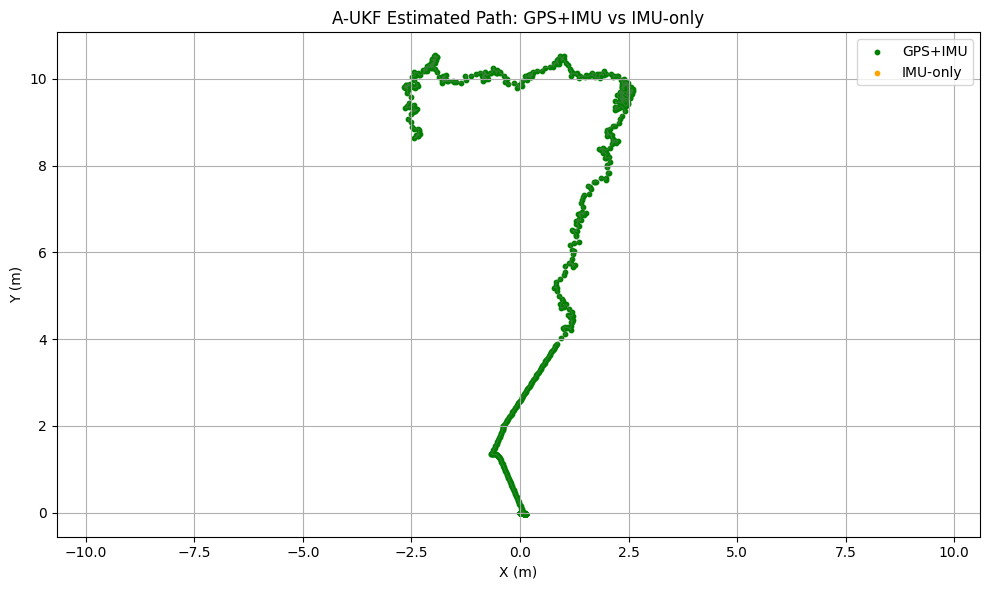

In [ ]:

# --- Run A-UKF ---
dt = imu_df['dt'].mean()
aekf = AdaptiveUKF(dt)

x_est, y_est, v_est = [], [], []
mode_log = []

for i in range(min(len(imu_df), len(gps_df))):
    x = imu_df['X_rot'].iloc[i]
    y = imu_df['Y_rot'].iloc[i]
    v = imu_df['speed'].iloc[i]
    yaw = imu_df['yaw'].iloc[i]
    aekf.predict(x, y, v, yaw)

    cov_x = gps_df['cov_x'].iloc[i]
    cov_y = gps_df['cov_y'].iloc[i]
    cov_v = gps_df['cov_v'].iloc[i]

    if cov_x < 1e-3 and cov_y < 1e-3:
        gps_x = gps_df['x_rot'].iloc[i]
        gps_y = gps_df['y_rot'].iloc[i]
        gps_v = gps_df['v'].iloc[i]
        aekf.update(gps_x, gps_y, gps_v, cov_x, cov_y, cov_v)
        mode_log.append("GPS+IMU")
    else:
        mode_log.append("IMU-only")
        print(f"[{i}] Skipping GPS update due to high noise.")

    x_est.append(aekf.x[0])
    y_est.append(aekf.x[1])
    v_est.append(aekf.x[2])

    estimated_df = pd.DataFrame({'x': x_est, 'y': y_est, 'v': v_est, 'mode': mode_log})

# --- Plot Estimated Path using matplotlib ---
plt.figure(figsize=(10, 6))

# Plot GPS+IMU points
gps_mask = estimated_df['mode'] == 'GPS+IMU'
plt.scatter(estimated_df[gps_mask]['x'], estimated_df[gps_mask]['y'], 
            c='green', label='GPS+IMU', s=10)

# Plot IMU-only points
imu_mask = estimated_df['mode'] == 'IMU-only'
plt.scatter(estimated_df[imu_mask]['x'], estimated_df[imu_mask]['y'], 
            c='orange', label='IMU-only', s=10)

plt.plot(x_est, y_est, color='gray', linewidth=0.8, alpha=0.4)

plt.title("A-UKF Estimated Path: GPS+IMU vs IMU-only")
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
